# When groups are not round: a merge tree, and DBSCAN

Aurora's security team suspects that some of last week's website sessions
were run by scripts (bots), not by shoppers. For every session they log two
numbers: how long it lasted, and how many pages it viewed. Nobody has marked
which sessions were bots.

This dataset is built **on purpose so that k-means cannot solve it**. The
notebook shows k-means failing, shows a second family of methods, the merge
tree (hierarchical clustering), failing the same way, and then shows a method
that succeeds, DBSCAN, because it asks a different question: not *which centre
is nearest?* but *is this point in a crowded place?* The handout's section 3
tells the same story in prose.

## 1. Setup

In [1]:
# pip install numpy==1.26.4 pandas==2.1.1 matplotlib==3.8.0 scikit-learn==1.3.1 scipy==1.11.3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from pathlib import Path

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

from retail_data import make_bot_sessions, TRUE_BOT_FRACTION

FIGURES = Path.cwd().parent / "Figures"
FIGURES.mkdir(exist_ok=True)

BLUE, TEAL, RUST, GOLD, GREY, INK = "#1F4E79", "#2E8B8B", "#B4483E", "#C9A227", "#B0B0B0", "#1A1A1A"

sessions = make_bot_sessions()
X = sessions[["session_duration_min", "pages_viewed"]].values
Xs = StandardScaler().fit_transform(X)
is_bot = (sessions["true_group"] == "bot").values

print(f"{len(sessions)} sessions, {TRUE_BOT_FRACTION:.0%} generated as bots "
      "(kept aside: no method below sees it)")
sessions.head()

1500 sessions, 12% generated as bots (kept aside: no method below sees it)


,session_duration_min,pages_viewed,true_group
0,5.435591,1.000000,human
1,2.808915,1.000000,human
2,6.927807,6.352220,human
3,0.200000,16.545770,human
4,7.041648,16.952852,human


## 2. Look at it first

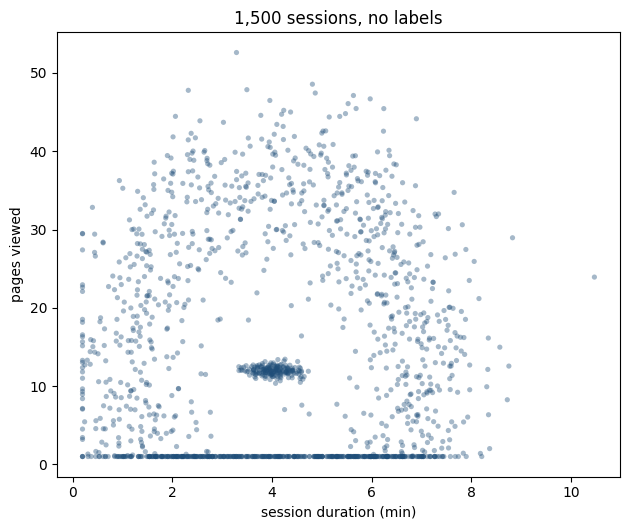

In [2]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.scatter(X[:, 0], X[:, 1], s=14, color=BLUE, alpha=.4, edgecolor="none")
ax.set_xlabel("session duration (min)"); ax.set_ylabel("pages viewed")
ax.set_title("1,500 sessions, no labels")
fig.tight_layout()
fig.savefig(FIGURES / "sessions_unlabelled.png", dpi=150)
plt.show()

Not four separate clouds this time: one dense smudge sitting inside a much
larger, looser ring, both centred in the same place. A script does the same
thing every time, so the bots pile up in a tight spot; people vary, so they
spread out around it. The natural split is *close to the middle* against
*far from it*. No straight cut can make that split.

## 3. k-means, applied anyway

k-means with $k = 2$, exactly as in notebook 01, then checked against the
true groups with the adjusted Rand index (ARI) from notebook 01: 1 means the
true groups recovered exactly, 0 means no better than a random split.

In [3]:
km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(Xs)
ari_km = adjusted_rand_score(is_bot, km.labels_)
print(f"k-means, k = 2: ARI = {ari_km:.3f}")
pd.crosstab(sessions["true_group"], km.labels_, rownames=["true"], colnames=["k-means cluster"])

k-means, k = 2: ARI = -0.046


k-means cluster,0,1
true,,
bot,0,180
human,540,780


An ARI just below 0: no better than chance. Every one of the 180 bots
ended up in one cluster, but so did 780 humans, and the other cluster holds
only humans. This is not bad luck with the start, and more restarts would not
fix it. k-means describes each group by a centre and gives every point to the
nearest centre, so its two groups are always the two halves of the plane on
either side of a straight line. The only way to cut this picture with a
straight line is through the middle, which cuts the ring in half and leaves
the bots on one side with half of the humans.

## 4. Hierarchical clustering: a tree of merges

A completely different idea. Start with every point as a group of its own.
Merge the two groups that are closest. Repeat, until everything is one group.
Every merge is recorded, and the record is a tree called a **dendrogram**: the
height at which two branches join says how far apart the two groups were when
they merged. Cutting the tree with a horizontal line gives a grouping; the
number of branches the line crosses is the number of groups, so choosing where
to cut is choosing $k$.

"Closest" needs a rule when groups have more than one point. scikit-learn's
default, **Ward linkage**, merges the two groups whose union is still the most
compact, meaning it adds the least to the within-cluster sum of squares of
notebook 01. For two single points, that is simply the two nearest.

Eight customers make the idea visible.

In [4]:
eight = np.array([[1.0, 1.0], [1.6, 1.3], [1.2, 2.3],      # A, B, C
                  [4.2, 4.0], [5.0, 4.4], [4.5, 5.3],      # D, E, F
                  [8.2, 1.6], [8.8, 2.6]])                 # G, H
letters = list("ABCDEFGH")
merges = linkage(eight, method="ward")

def members(node):
    """Letters inside a node of the merge tree (nodes 0-7 are the points themselves)."""
    if node < len(eight):
        return letters[int(node)]
    left, right = merges[int(node) - len(eight), :2]
    return members(left) + members(right)

for step, (left, right, height, size) in enumerate(merges, start=1):
    print(f"merge {step}: {members(left):<4} + {members(right):<4} at height {height:6.3f}  ->  group of {int(size)}")

merge 1: A    + B    at height  0.671  ->  group of 2
merge 2: D    + E    at height  0.894  ->  group of 2
merge 3: G    + H    at height  1.166  ->  group of 2
merge 4: F    + DE   at height  1.275  ->  group of 3
merge 5: C    + AB   at height  1.333  ->  group of 3
merge 6: GH   + FDE  at height  7.193  ->  group of 5
merge 7: CAB  + GHFDE at height 10.236  ->  group of 8


The first three merges join the three closest pairs (A with B, D with E,
G with H). Then C and F join their neighbours, which leaves three groups,
ABC, DEF and GH, and the next merge has to bridge a real gap: its height jumps
from 1.3 to 7.2. A long vertical stretch with no merge in it is the tree's way
of saying *here is a natural number of groups*. Cutting there gives three.

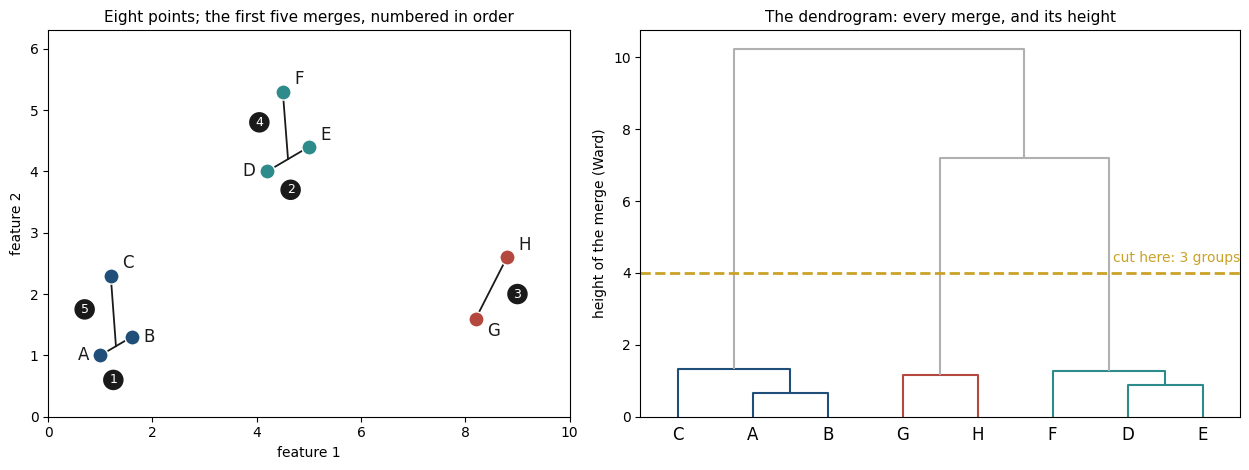

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.6, 4.8), gridspec_kw={"width_ratios": [1, 1.15]})
LETTER_AT = {"A": (-.22, 0, "right"), "B": (.22, 0, "left"), "C": (.22, .2, "left"),
             "D": (-.22, 0, "right"), "E": (.22, .2, "left"), "F": (.22, .2, "left"),
             "G": (.22, -.2, "left"), "H": (.22, .2, "left")}
cut = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(eight)
colours = {lab: c for lab, c in zip(dict.fromkeys(cut), (BLUE, TEAL, RUST))}
for (x, y), name, lab in zip(eight, letters, cut):
    ax1.scatter(x, y, s=120, color=colours[lab], edgecolor="white", zorder=3)
    dx, dy, ha = LETTER_AT[name]              # letters placed clear of the merge segments
    ax1.text(x + dx, y + dy, name, fontsize=12, color=INK, ha=ha, va="center")
# Each of the first five merges drawn as a segment between the two groups it joins
# (a group of several points is represented by its mean), numbered where the number
# stays clear of points and letters.
number_at = {1: (1.25, 0.6), 2: (4.65, 3.7), 3: (9.0, 2.0), 4: (4.05, 4.8), 5: (0.7, 1.75)}
group_mean = lambda node: eight[[letters.index(c) for c in members(node)]].mean(axis=0)
for step, (left, right, height, size) in enumerate(merges[:5], start=1):
    p, q = group_mean(left), group_mean(right)
    ax1.plot([p[0], q[0]], [p[1], q[1]], color=INK, lw=1.3, zorder=2)
    ax1.text(*number_at[step], str(step), fontsize=9, color="white", ha="center", va="center",
             bbox=dict(boxstyle="circle", facecolor=INK, edgecolor="none"), zorder=4)
ax1.set_xlim(0, 10); ax1.set_ylim(0, 6.3)
ax1.set_xlabel("feature 1"); ax1.set_ylabel("feature 2")
ax1.set_title("Eight points; the first five merges, numbered in order", fontsize=11)

from scipy.cluster.hierarchy import set_link_color_palette
set_link_color_palette([BLUE, RUST, TEAL])     # the same colours as the points on the left
dendrogram(merges, labels=letters, ax=ax2, color_threshold=4.0, above_threshold_color=GREY)
set_link_color_palette(None)
ax2.axhline(4.0, color=GOLD, linestyle="--", linewidth=2)
ax2.text(8.4 * 10 - 4, 4.3, "cut here: 3 groups", color=GOLD, fontsize=10, ha="right")
ax2.set_ylabel("height of the merge (Ward)")
ax2.set_title("The dendrogram: every merge, and its height", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "merge_tree.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

Now the same method on the 1,500 sessions, cut at two groups.

In [6]:
ward = AgglomerativeClustering(n_clusters=2, linkage="ward").fit(Xs)
ari_ward = adjusted_rand_score(is_bot, ward.labels_)
print(f"hierarchical clustering, Ward linkage, cut at 2 groups: ARI = {ari_ward:.3f}")
pd.crosstab(sessions["true_group"], ward.labels_, rownames=["true"], colnames=["Ward cluster"])

hierarchical clustering, Ward linkage, cut at 2 groups: ARI = -0.062


Ward cluster,0,1
true,,
bot,180,0
human,827,493


No better than k-means, and for the same reason. Ward linkage merges
whatever keeps groups compact, which is exactly what k-means rewards, so it
ends up wanting the same two compact halves. The tree is a different
procedure built on the same idea of what a group is.

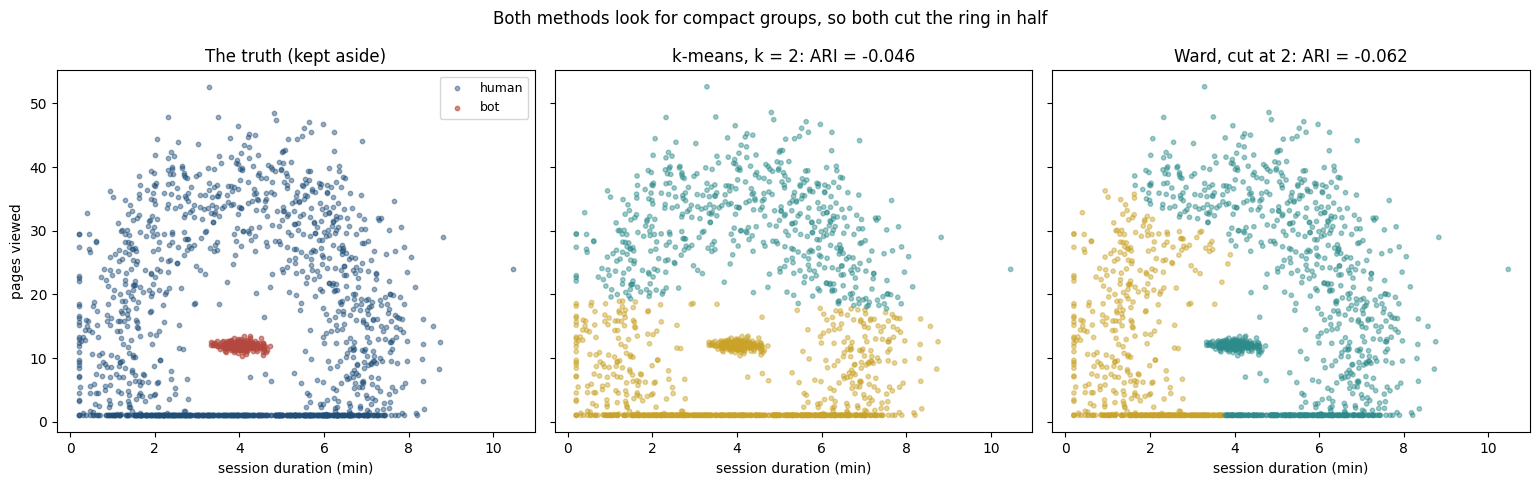

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.9), sharex=True, sharey=True)
axes[0].scatter(X[~is_bot, 0], X[~is_bot, 1], s=10, alpha=.45, color=BLUE, label="human")
axes[0].scatter(X[is_bot, 0], X[is_bot, 1], s=10, alpha=.6, color=RUST, label="bot")
axes[0].legend(fontsize=9, loc="upper right")
axes[0].set_title("The truth (kept aside)")
for ax, labels, name, ari in ((axes[1], km.labels_, "k-means, k = 2", ari_km),
                              (axes[2], ward.labels_, "Ward, cut at 2", ari_ward)):
    ax.scatter(X[:, 0], X[:, 1], s=10, alpha=.45, color=np.where(labels == 0, TEAL, GOLD))
    ax.set_title(f"{name}: ARI = {ari:.3f}")
for ax in axes:
    ax.set_xlabel("session duration (min)")
axes[0].set_ylabel("pages viewed")
fig.suptitle("Both methods look for compact groups, so both cut the ring in half", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "round_methods_fail.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

## 5. DBSCAN: crowded places, not centres

**DBSCAN** (density-based spatial clustering of applications with noise)
looks at each point's neighbourhood: the disc of radius `eps` around it.

- A point is a **core point** if at least `min_samples` points lie in its
  disc, the point itself included.
- A point that is not core, but lies in the disc of a core point, is a
  **border point**: it belongs to that core point's group, but it cannot
  extend the group further.
- Every other point is **noise**: it belongs to no group.

A group is then a chain of core points, each inside another's disc, together
with the border points around them. Nothing here mentions a centre or a
shape, so a group can be a ring, a band, or any connected crowded region. And
DBSCAN does not need $k$: the number of groups is whatever the chains turn out
to be.

Twelve points, with `eps = 0.9` and `min_samples = 4`, show all three kinds.

In [8]:
twelve = np.array([[2.0, 2.0], [2.6, 2.3], [2.2, 2.9], [3.0, 2.8], [2.7, 3.5], [3.5, 3.4],
                   [1.6, 2.7], [3.3, 2.2], [4.4, 3.9], [5.3, 4.5], [6.2, 1.4], [1.0, 5.6]])
toy = DBSCAN(eps=0.9, min_samples=4).fit(twelve)
core = np.zeros(len(twelve), dtype=bool); core[toy.core_sample_indices_] = True
noise = toy.labels_ == -1
border = ~core & ~noise
in_disc = (NearestNeighbors(radius=0.9).fit(twelve)
           .radius_neighbors(twelve, return_distance=False))
for i in range(len(twelve)):
    kind = "core" if core[i] else ("border" if border[i] else "noise")
    print(f"point {i:>2}: {len(in_disc[i])} in its disc (itself included) -> {kind}")
print(f"\n{core.sum()} core, {border.sum()} border, {noise.sum()} noise; groups found: {len(set(toy.labels_) - {-1})}")

point  0: 3 in its disc (itself included) -> border
point  1: 5 in its disc (itself included) -> core
point  2: 5 in its disc (itself included) -> core
point  3: 6 in its disc (itself included) -> core
point  4: 4 in its disc (itself included) -> core
point  5: 3 in its disc (itself included) -> border
point  6: 3 in its disc (itself included) -> border
point  7: 3 in its disc (itself included) -> border
point  8: 1 in its disc (itself included) -> noise
point  9: 1 in its disc (itself included) -> noise
point 10: 1 in its disc (itself included) -> noise
point 11: 1 in its disc (itself included) -> noise

4 core, 4 border, 4 noise; groups found: 1


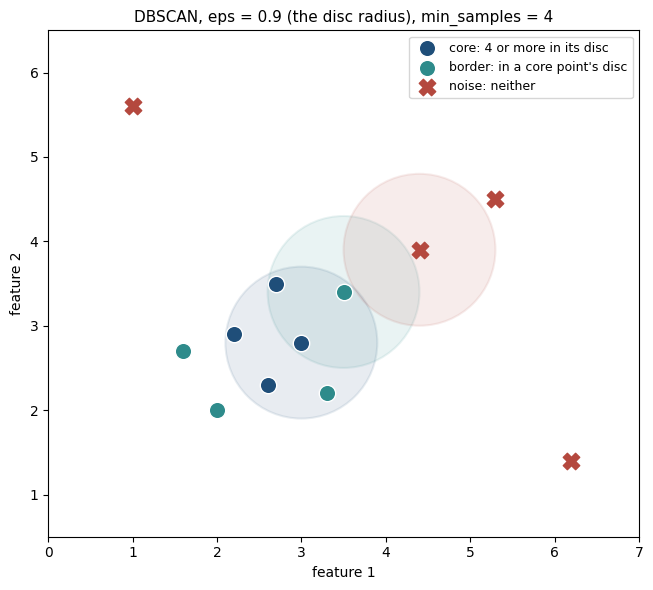

In [9]:
fig, ax = plt.subplots(figsize=(7.6, 6.0))
for i, colour in ((3, BLUE), (5, TEAL), (8, RUST)):      # one disc of each kind
    ax.add_patch(Circle(twelve[i], 0.9, facecolor=colour, alpha=.10, edgecolor=colour, linewidth=1.5))
ax.scatter(*twelve[core].T, s=140, color=BLUE, edgecolor="white", zorder=3, label="core: 4 or more in its disc")
ax.scatter(*twelve[border].T, s=140, color=TEAL, edgecolor="white", zorder=3, label="border: in a core point's disc")
ax.scatter(*twelve[noise].T, s=140, color=RUST, marker="X", zorder=3, label="noise: neither")
ax.set_xlim(0, 7); ax.set_ylim(0.5, 6.5); ax.set_aspect("equal")
ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
ax.set_title("DBSCAN, eps = 0.9 (the disc radius), min_samples = 4", fontsize=11)
ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()
fig.savefig(FIGURES / "dbscan_points.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

The three shaded discs are one of each kind. The blue one belongs to a core
point and holds at least four points. The teal one belongs to a border point:
fewer than four points in its disc, but it sits inside a core point's disc, so
it joins that group. The rust one belongs to a noise point: it is not even far
from the group, but nothing within 0.9 of it is a core point.

### 5.1 Choosing `eps`

`eps` is the parameter that matters most. Too small, and even the dense bot
core breaks up into noise. Too large, and the discs of the ring reach into the
core, chaining everything into one group.

A **k-distance plot** suggests a value. For every point, measure the distance
to its 10th nearest neighbour (10 being the `min_samples` used below), and
sort those distances. Points in crowded places have a short distance, points
in sparse places a long one, and the sorted curve bends upward where crowded
gives way to sparse. Put `eps` near the bend.

sessions whose 10th neighbour is farther than 0.30: 65 of 1500


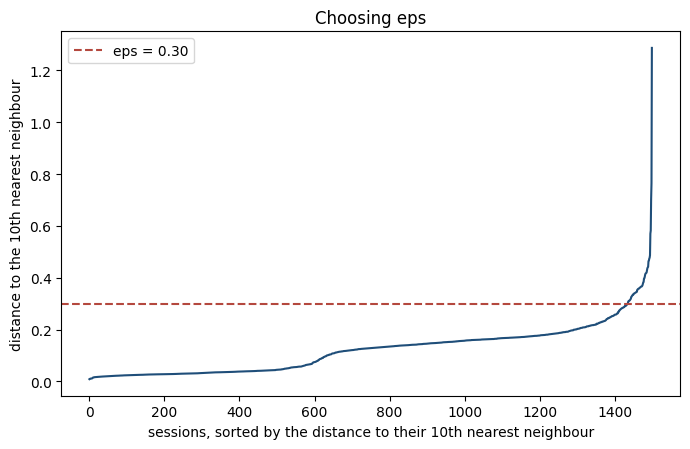

In [10]:
min_samples = 10
distances, _ = NearestNeighbors(n_neighbors=min_samples).fit(Xs).kneighbors(Xs)
kth_distance = np.sort(distances[:, -1])

print(f"sessions whose 10th neighbour is farther than 0.30: {(kth_distance > 0.30).sum()} of {len(Xs)}")

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.plot(kth_distance, color=BLUE)
ax.axhline(0.30, color=RUST, linestyle="--", label="eps = 0.30")
ax.set_xlabel("sessions, sorted by the distance to their 10th nearest neighbour")
ax.set_ylabel("distance to the 10th nearest neighbour")
ax.set_title("Choosing eps")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "k_distance_plot.png", dpi=150)
plt.show()

The curve stays low and flat for most sessions and turns sharply upward at the
right-hand end. `eps = 0.30` sits just above the flat part: only 65 of the 1,500
sessions have their 10th neighbour farther away than that, as the next cell
prints. (`kneighbors`
counts each point as its own first neighbour, so the 10th column is the
distance to the 9th other point; that matches DBSCAN, which also counts the
point itself in `min_samples`.)

### 5.2 DBSCAN on the sessions

In [11]:
db = DBSCAN(eps=0.30, min_samples=min_samples).fit(Xs)
ari_db = adjusted_rand_score(is_bot, db.labels_)
print(f"DBSCAN (eps = 0.30, min_samples = 10): ARI = {ari_db:.3f}")
print(f"core points: {len(db.core_sample_indices_)} of {len(Xs)}, noise points: {(db.labels_ == -1).sum()}")
pd.crosstab(sessions["true_group"], db.labels_, rownames=["true"], colnames=["DBSCAN label (-1 = noise)"])

DBSCAN (eps = 0.30, min_samples = 10): ARI = 0.941
core points: 1435 of 1500, noise points: 13


DBSCAN label (-1 = noise),-1,0,1
true,,,
bot,0,0,180
human,13,1303,4


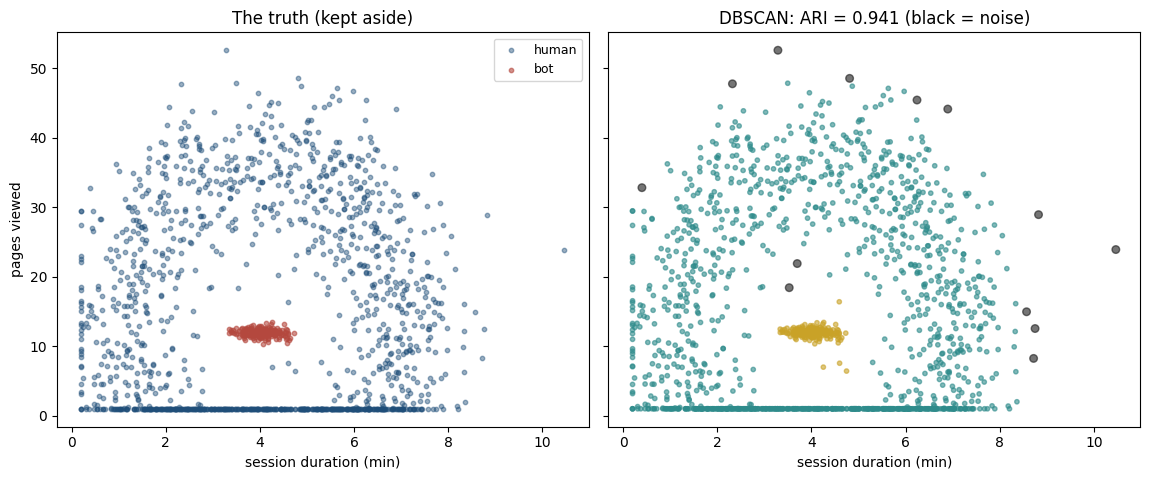

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.6, 4.9), sharex=True, sharey=True)
ax1.scatter(X[~is_bot, 0], X[~is_bot, 1], s=10, alpha=.45, color=BLUE, label="human")
ax1.scatter(X[is_bot, 0], X[is_bot, 1], s=10, alpha=.6, color=RUST, label="bot")
ax1.legend(fontsize=9, loc="upper right"); ax1.set_title("The truth (kept aside)")
colour = np.select([db.labels_ == 0, db.labels_ == 1], [TEAL, GOLD], default=INK)
ax2.scatter(X[:, 0], X[:, 1], s=np.where(db.labels_ == -1, 30, 10), alpha=.6, color=colour,
            marker="o")
ax2.set_title(f"DBSCAN: ARI = {ari_db:.3f} (black = noise)")
for ax in (ax1, ax2):
    ax.set_xlabel("session duration (min)")
ax1.set_ylabel("pages viewed")
fig.tight_layout()
fig.savefig(FIGURES / "dbscan_result.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

DBSCAN finds the split almost exactly: all 180 bots in one group, 1,303 of
the 1,320 humans in the other, 4 humans placed with the bots, and 13 sessions
left as noise. Who are those 13?

In [13]:
print(sessions.loc[db.labels_ == -1, "true_group"].value_counts().to_string())

# Where are they? Distance from the middle of the bot core, in standardised units.
core_middle = Xs[is_bot].mean(axis=0)
radius = np.linalg.norm(Xs - core_middle, axis=1)
print(f"\nfarthest bot from the middle: {radius[is_bot].max():.2f}")
print(f"humans: 5% are closer than {np.percentile(radius[~is_bot], 5):.2f}, 95% closer than {np.percentile(radius[~is_bot], 95):.2f}")
print("the 13 noise sessions:", np.sort(radius[db.labels_ == -1]).round(2))

true_group
human    13

farthest bot from the middle: 0.33
humans: 5% are closer than 0.83, 95% closer than 2.19
the 13 noise sessions: [0.54 0.76 2.16 2.23 2.23 2.32 2.6  2.71 2.76 2.76 2.8  3.06 3.17]


All 13 are humans, and they sit where the data is thin. Two (at 0.54 and 0.76
from the middle) are in the gap between the bot core, which ends at 0.33, and
the ring; the other eleven are at 2.16 or farther, on the ring's sparse outer
edge, where 95% of humans are already closer to the middle (2.19). DBSCAN's answer for them is not
"bot" or "human" but *not confidently either*, which is more useful to a
security analyst than a forced label.

## 6. Which grouping looks better, without the answer key?

Aurora's analysts would not have the true groups. They could compute the
silhouette of notebook 01, which needs only the data and the grouping. Compare
it with the ARI, which needs the truth.

In [14]:
kept = db.labels_ != -1                       # the silhouette has no place for noise points
print(f"k-means, k = 2: silhouette {silhouette_score(Xs, km.labels_):.3f}   ARI {ari_km:+.3f}")
print(f"DBSCAN        : silhouette {silhouette_score(Xs[kept], db.labels_[kept]):.3f}   ARI {ari_db:+.3f}")

from sklearn.metrics import silhouette_samples
per_point = silhouette_samples(Xs[kept], db.labels_[kept])
ring = db.labels_[kept] == 0                  # DBSCAN's group 0 is the ring of humans
print(f"ring points with a negative silhouette: {(per_point[ring] < 0).mean():.1%}")

k-means, k = 2: silhouette 0.401   ARI -0.046
DBSCAN        : silhouette -0.106   ARI +0.941
ring points with a negative silhouette: 99.2%


The silhouette prefers the wrong answer. k-means' useless split scores 0.401,
because two compact halves are what the silhouette rewards. DBSCAN's correct
answer scores below zero: a ring is not compact, and 99.2% of the ring's points
have a negative silhouette, because on average they are closer to the bot core
in the middle than to the rest of their own ring, most of which lies across
the circle from them. The
silhouette measures roundness, and it cannot tell you that roundness is the
wrong question for this data. Only looking at the picture, or a ground truth,
tells you that.

## 7. The predictable mistake

After notebook 01, the reasonable conclusion is "k-means found the groups, so
clustering works." **The instinct is right about k-means on round clouds; it
is wrong about clustering being one thing.** k-means and Ward linkage both
define a group as *compact*; DBSCAN defines it as *a crowded connected
region*. On nested shapes like this one the two definitions disagree, and
which is right is a property of the data, not of the algorithm. That is why
both notebooks started by looking at the scatter before running anything.

## Summary

- On a dense core inside a ring, k-means (ARI −0.046) and hierarchical
  clustering with Ward linkage (ARI −0.062) both fail: both look for compact
  groups and cut the ring in half.
- Hierarchical clustering builds a tree of merges; a long stretch of the tree
  with no merge suggests the number of groups, and cutting the tree chooses it.
- DBSCAN groups points by how crowded their neighbourhood is, with no centres
  and no $k$. With `eps` read off the k-distance plot it recovers the split
  (ARI 0.941) and leaves 13 ambiguous sessions as noise.
- The silhouette, which needs no answer key, prefers k-means' wrong split to
  DBSCAN's correct one: it rewards compactness, whatever the data's shape.